# Heart Disease Prediction

## Project Objective

The objective of this project is to analyze patient cardiovascular data and build a Machine Learning model to predict the presence of heart disease.

### Project Tasks
1. Perform data analysis on the given dataset.
2. Build Machine Learning models to predict heart disease.
3. Compare the performance of multiple models.
4. Select the best-performing model for production.
5. Provide suggestions to the hospital based on the predictions.
6. Document the challenges faced during the project and the techniques used to solve them.

### Developed By : Sindhu S

In [1]:
# Import Required Libraries

import pandas as pd
import numpy as np

In [2]:
# Load the Dataset

values = pd.read_csv("values.csv")
labels = pd.read_csv("labels.csv")

In [3]:
# Check the Shape of the Datasets

print("Values Shape:", values.shape)
print("Labels Shape:", labels.shape)

Values Shape: (180, 14)
Labels Shape: (180, 2)


In [4]:
# Display the First Five Rows of the Values Dataset

values.head()

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0


In [5]:
# Display the First Five Rows of the Labels Dataset

labels.head()

,patient_id,heart_disease_present
0,0z64un,0
1,ryoo3j,0
2,yt1s1x,1
3,l2xjde,1
4,oyt4ek,0


In [6]:
# Display Column Names

values.columns

Index(['patient_id', 'slope_of_peak_exercise_st_segment', 'thal',
       'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels',
       'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results',
       'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age',
       'max_heart_rate_achieved', 'exercise_induced_angina'],
      dtype='object')

In [7]:
# Check Data Types

values.dtypes

patient_id                               object
slope_of_peak_exercise_st_segment         int64
thal                                     object
resting_blood_pressure                    int64
chest_pain_type                           int64
num_major_vessels                         int64
fasting_blood_sugar_gt_120_mg_per_dl      int64
resting_ekg_results                       int64
serum_cholesterol_mg_per_dl               int64
oldpeak_eq_st_depression                float64
sex                                       int64
age                                       int64
max_heart_rate_achieved                   int64
exercise_induced_angina                   int64
dtype: object

In [8]:
# Check Missing Values in the Values Dataset

values.isnull().sum()

patient_id                              0
slope_of_peak_exercise_st_segment       0
thal                                    0
resting_blood_pressure                  0
chest_pain_type                         0
num_major_vessels                       0
fasting_blood_sugar_gt_120_mg_per_dl    0
resting_ekg_results                     0
serum_cholesterol_mg_per_dl             0
oldpeak_eq_st_depression                0
sex                                     0
age                                     0
max_heart_rate_achieved                 0
exercise_induced_angina                 0
dtype: int64

In [9]:
# Check Missing Values in the Labels Dataset

labels.isnull().sum()

patient_id               0
heart_disease_present    0
dtype: int64

In [10]:
# Statistical Summary of Numerical Features

values.describe()

,slope_of_peak_exercise_st_segment,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,1.550000,131.311111,3.155556,0.694444,0.161111,1.050000,249.211111,1.010000,0.688889,54.811111,149.483333,0.316667
std,0.618838,17.010443,0.938454,0.969347,0.368659,0.998742,52.717969,1.121357,0.464239,9.334737,22.063513,0.466474
min,1.000000,94.000000,1.000000,0.000000,0.000000,0.000000,126.000000,0.000000,0.000000,29.000000,96.000000,0.000000
25%,1.000000,120.000000,3.000000,0.000000,0.000000,0.000000,213.750000,0.000000,0.000000,48.000000,132.000000,0.000000
50%,1.000000,130.000000,3.000000,0.000000,0.000000,2.000000,245.500000,0.800000,1.000000,55.000000,152.000000,0.000000
75%,2.000000,140.000000,4.000000,1.000000,0.000000,2.000000,281.250000,1.600000,1.000000,62.000000,166.250000,1.000000
max,3.000000,180.000000,4.000000,3.000000,1.000000,2.000000,564.000000,6.200000,1.000000,77.000000,202.000000,1.000000


In [11]:
# Check Heart Disease Target Distribution

labels["heart_disease_present"].value_counts()

heart_disease_present
0    100
1     80
Name: count, dtype: int64

In [12]:
# Calculate Heart Disease Target Percentages

labels["heart_disease_present"].value_counts(normalize=True) * 100

heart_disease_present
0    55.555556
1    44.444444
Name: proportion, dtype: float64

In [13]:
# Display Statistical Summary of All Numerical Features

pd.set_option("display.max_columns", None)

values.describe()

,slope_of_peak_exercise_st_segment,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina
count,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000,180.000000
mean,1.550000,131.311111,3.155556,0.694444,0.161111,1.050000,249.211111,1.010000,0.688889,54.811111,149.483333,0.316667
std,0.618838,17.010443,0.938454,0.969347,0.368659,0.998742,52.717969,1.121357,0.464239,9.334737,22.063513,0.466474
min,1.000000,94.000000,1.000000,0.000000,0.000000,0.000000,126.000000,0.000000,0.000000,29.000000,96.000000,0.000000
25%,1.000000,120.000000,3.000000,0.000000,0.000000,0.000000,213.750000,0.000000,0.000000,48.000000,132.000000,0.000000
50%,1.000000,130.000000,3.000000,0.000000,0.000000,2.000000,245.500000,0.800000,1.000000,55.000000,152.000000,0.000000
75%,2.000000,140.000000,4.000000,1.000000,0.000000,2.000000,281.250000,1.600000,1.000000,62.000000,166.250000,1.000000
max,3.000000,180.000000,4.000000,3.000000,1.000000,2.000000,564.000000,6.200000,1.000000,77.000000,202.000000,1.000000


In [14]:
# Display Unique Values in Each Column

for column in values.columns:
    print(f"\n{column}:")
    print(values[column].unique())


patient_id:
['0z64un' 'ryoo3j' 'yt1s1x' 'l2xjde' 'oyt4ek' 'ldukkw' '2gbyh9' 'daa9kp'
 '3nwy2n' '1r508r' 'ldg4b9' 'xc17yq' 'mpggsq' 'zlyac8' 'f06u72' '2fv3rc'
 'qyrkxn' '237mql' 'mc750a' '30v796' 'cvux3j' 'k8899q' 'jhdvtb' '5g9v0h'
 '83asqd' 'gla0im' 'zzmfh7' 'f4g1ay' 'lek9q9' '8265rl' '6017a1' 'z7xkou'
 'k7ef7h' '0n5fu0' '55xksg' 'pjgqa3' 'xkdz7j' 'tpuevg' 'ascl42' '1xwoe6'
 'ty4ik8' 'gx6yxl' 'hlmts5' 'yx0q6k' 'ep1o51' 'gj1e5z' '6219kl' 'rp9g6x'
 '1aeaff' 'y3prof' '3drd48' 'ejo7p3' 'r7y4i1' 'mznwxv' '27oevk' 'jwqi3k'
 '328lkl' 'tlk9o8' 'aq2vrq' 'ilogfb' 'rv6siv' 'm2a4i9' 'pwigd8' 'qwapdq'
 '4sd1xn' 'nck22c' 'm6zksp' 'f70grj' 'k1art8' 'mcwqgs' '3jsjqk' 'ik7hfs'
 'qwj1yf' 'qvhk9e' 'igwnqo' '4v0q7o' 'hh2awp' 'vfjppl' '6lu42b' 'shiro4'
 '3wl3z4' 'ebioez' '37c0vm' 'v52zcs' '6nkcaw' 'hfp05i' 'grfxwd' 'bvcxah'
 'i49srr' '93dbhq' 'jscmp8' 'zaytyf' 'wze8qm' 'w3933i' '7uch9x' 'dy5hxt'
 'c0gkqc' 'z5g5p3' 'h3uzv8' 'bthqr4' 'rfj25e' '9f92et' '24fopx' 'ldr1mz'
 'wokyol' 'p5orwa' 's8dx1q' '7kf275' '

## Exploratory Data Analysis

In [15]:
# Check Duplicate Patient IDs

values["patient_id"].duplicated().sum()

np.int64(0)

In [16]:
# Check Target Distribution

target_counts = labels["heart_disease_present"].value_counts()

print("No Heart Disease (0):", target_counts.get(0, 0))
print("Heart Disease (1):", target_counts.get(1, 0))

No Heart Disease (0): 100
Heart Disease (1): 80


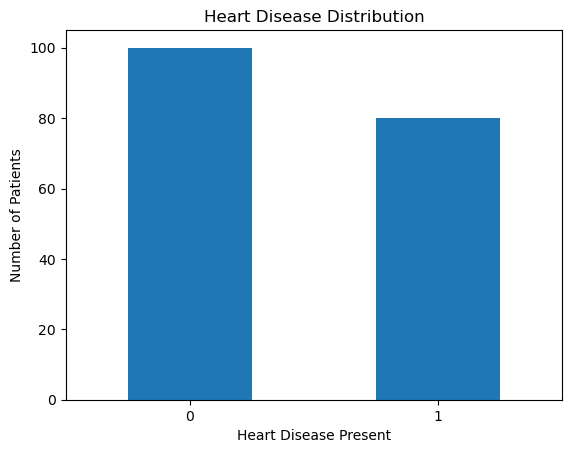

In [17]:
# Visualize Heart Disease Distribution

import matplotlib.pyplot as plt

labels["heart_disease_present"].value_counts().plot(
    kind="bar"
)

plt.title("Heart Disease Distribution")
plt.xlabel("Heart Disease Present")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.show()

In [18]:
# Combine Patient Features with Heart Disease Labels

df = pd.merge(
    values,
    labels,
    on="patient_id"
)

df.head()

,patient_id,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,0z64un,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,ryoo3j,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,yt1s1x,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,l2xjde,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,oyt4ek,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


In [19]:
# Check Combined Dataset Shape

print("Combined Dataset Shape:", df.shape)

Combined Dataset Shape: (180, 15)


In [20]:
# Display Combined Dataset Information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   patient_id                            180 non-null    object 
 1   slope_of_peak_exercise_st_segment     180 non-null    int64  
 2   thal                                  180 non-null    object 
 3   resting_blood_pressure                180 non-null    int64  
 4   chest_pain_type                       180 non-null    int64  
 5   num_major_vessels                     180 non-null    int64  
 6   fasting_blood_sugar_gt_120_mg_per_dl  180 non-null    int64  
 7   resting_ekg_results                   180 non-null    int64  
 8   serum_cholesterol_mg_per_dl           180 non-null    int64  
 9   oldpeak_eq_st_depression              180 non-null    float64
 10  sex                                   180 non-null    int64  
 11  age                

In [21]:
# Check Missing Values in the Combined Dataset

df.isnull().sum()

patient_id                              0
slope_of_peak_exercise_st_segment       0
thal                                    0
resting_blood_pressure                  0
chest_pain_type                         0
num_major_vessels                       0
fasting_blood_sugar_gt_120_mg_per_dl    0
resting_ekg_results                     0
serum_cholesterol_mg_per_dl             0
oldpeak_eq_st_depression                0
sex                                     0
age                                     0
max_heart_rate_achieved                 0
exercise_induced_angina                 0
heart_disease_present                   0
dtype: int64

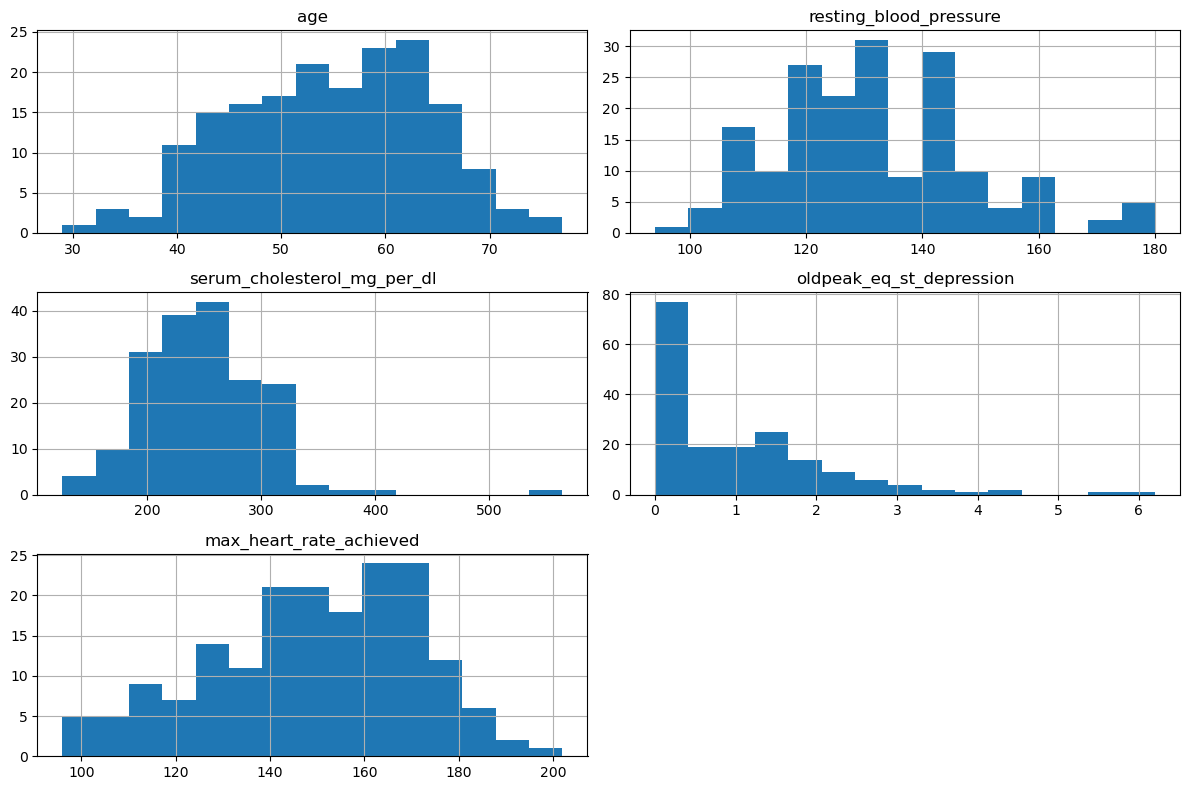

In [22]:
# Distribution of Numerical Features

numerical_columns = [
    "age",
    "resting_blood_pressure",
    "serum_cholesterol_mg_per_dl",
    "oldpeak_eq_st_depression",
    "max_heart_rate_achieved"
]

df[numerical_columns].hist(
    figsize=(12, 8),
    bins=15
)

plt.tight_layout()
plt.show()

In [23]:
# Summary Statistics of Numerical Features

df[numerical_columns].describe()

,age,resting_blood_pressure,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,max_heart_rate_achieved
count,180.000000,180.000000,180.000000,180.000000,180.000000
mean,54.811111,131.311111,249.211111,1.010000,149.483333
std,9.334737,17.010443,52.717969,1.121357,22.063513
min,29.000000,94.000000,126.000000,0.000000,96.000000
25%,48.000000,120.000000,213.750000,0.000000,132.000000
50%,55.000000,130.000000,245.500000,0.800000,152.000000
75%,62.000000,140.000000,281.250000,1.600000,166.250000
max,77.000000,180.000000,564.000000,6.200000,202.000000


In [24]:
# Numerical Features by Heart Disease Status

df.groupby("heart_disease_present")[numerical_columns].mean()

,age,resting_blood_pressure,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,max_heart_rate_achieved
heart_disease_present,,,,,
0,53.66,130.12,245.46,0.62700,156.87
1,56.25,132.80,253.90,1.48875,140.25


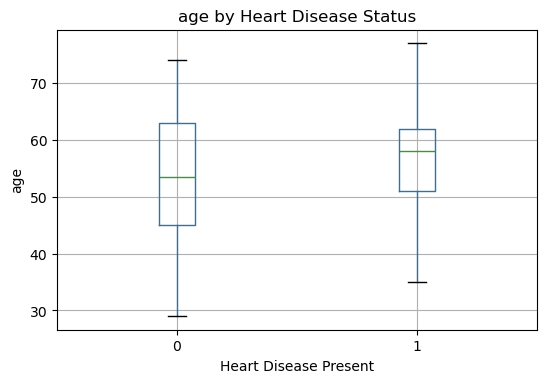

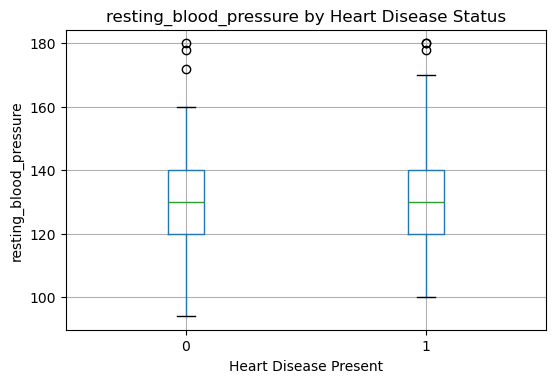

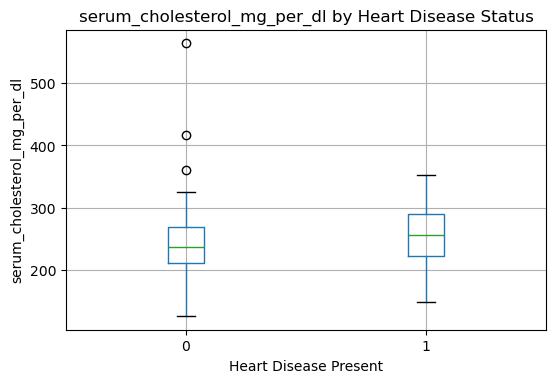

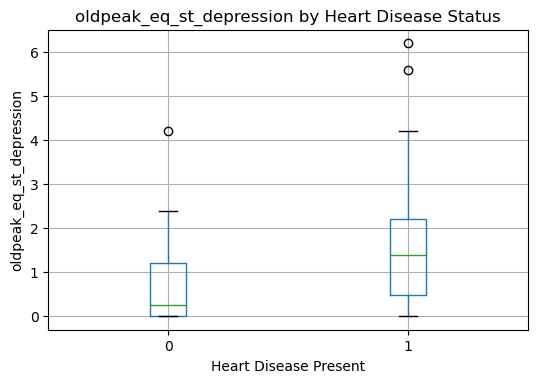

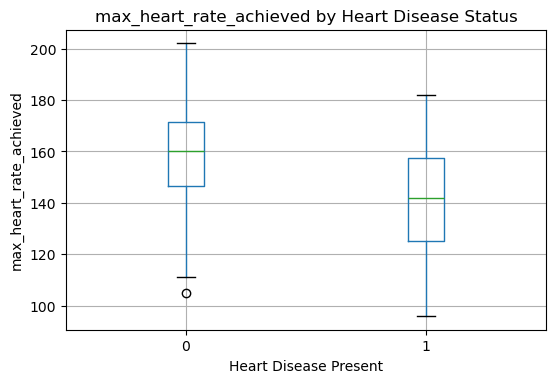

In [25]:
# Boxplots of Numerical Features by Heart Disease Status

for column in numerical_columns:
    df.boxplot(
        column=column,
        by="heart_disease_present",
        figsize=(6, 4)
    )
    
    plt.title(f"{column} by Heart Disease Status")
    plt.suptitle("")
    plt.xlabel("Heart Disease Present")
    plt.ylabel(column)
    plt.show()

In [26]:
# Define Categorical and Binary Features

categorical_columns = [
    "thal",
    "chest_pain_type",
    "slope_of_peak_exercise_st_segment",
    "num_major_vessels",
    "fasting_blood_sugar_gt_120_mg_per_dl",
    "resting_ekg_results",
    "sex",
    "exercise_induced_angina"
]

categorical_columns

['thal',
 'chest_pain_type',
 'slope_of_peak_exercise_st_segment',
 'num_major_vessels',
 'fasting_blood_sugar_gt_120_mg_per_dl',
 'resting_ekg_results',
 'sex',
 'exercise_induced_angina']

In [27]:
# Display Category Counts

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts())


thal:
thal
normal               98
reversible_defect    74
fixed_defect          8
Name: count, dtype: int64

chest_pain_type:
chest_pain_type
4    82
3    57
2    28
1    13
Name: count, dtype: int64

slope_of_peak_exercise_st_segment:
slope_of_peak_exercise_st_segment
1    93
2    75
3    12
Name: count, dtype: int64

num_major_vessels:
num_major_vessels
0    106
1     37
2     23
3     14
Name: count, dtype: int64

fasting_blood_sugar_gt_120_mg_per_dl:
fasting_blood_sugar_gt_120_mg_per_dl
0    151
1     29
Name: count, dtype: int64

resting_ekg_results:
resting_ekg_results
2    94
0    85
1     1
Name: count, dtype: int64

sex:
sex
1    124
0     56
Name: count, dtype: int64

exercise_induced_angina:
exercise_induced_angina
0    123
1     57
Name: count, dtype: int64


In [28]:
# Categorical Features by Heart Disease Status

for column in categorical_columns:
    print(f"\n{column}:")
    print(pd.crosstab(df[column], df["heart_disease_present"]))


thal:
heart_disease_present   0   1
thal                         
fixed_defect            4   4
normal                 78  20
reversible_defect      18  56

chest_pain_type:
heart_disease_present   0   1
chest_pain_type              
1                       9   4
2                      24   4
3                      44  13
4                      23  59

slope_of_peak_exercise_st_segment:
heart_disease_present               0   1
slope_of_peak_exercise_st_segment        
1                                  68  25
2                                  28  47
3                                   4   8

num_major_vessels:
heart_disease_present   0   1
num_major_vessels            
0                      77  29
1                      15  22
2                       6  17
3                       2  12

fasting_blood_sugar_gt_120_mg_per_dl:
heart_disease_present                  0   1
fasting_blood_sugar_gt_120_mg_per_dl        
0                                     84  67
1                        

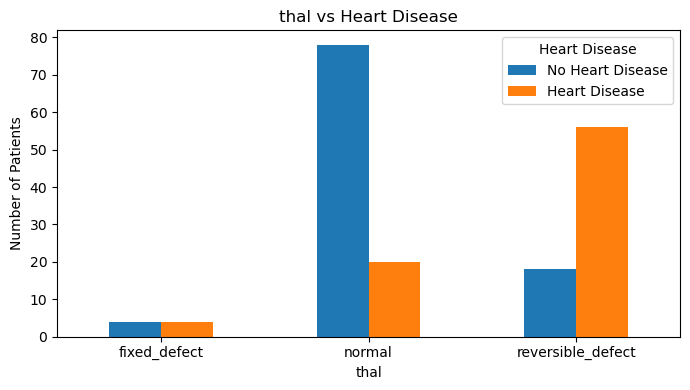

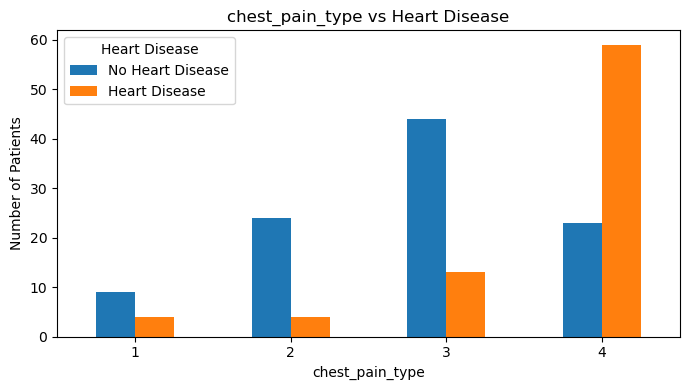

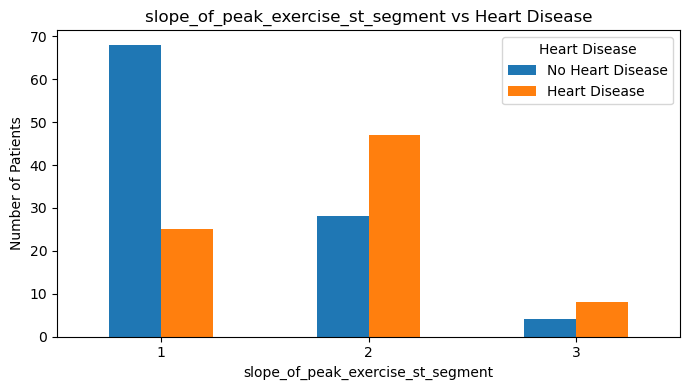

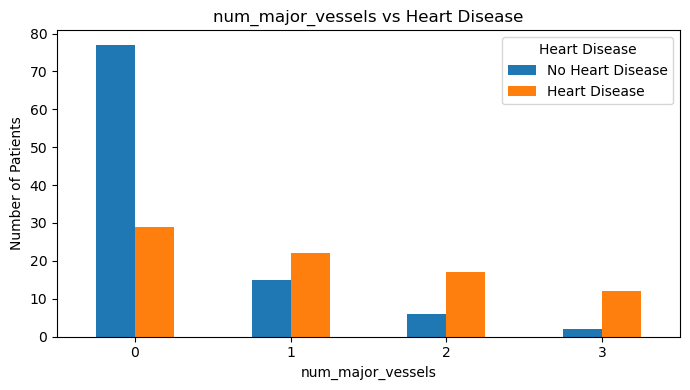

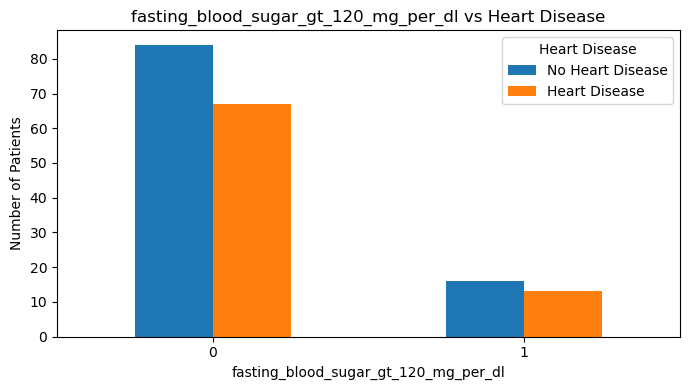

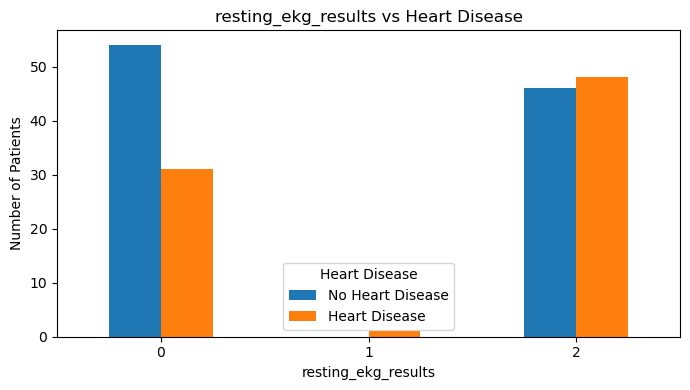

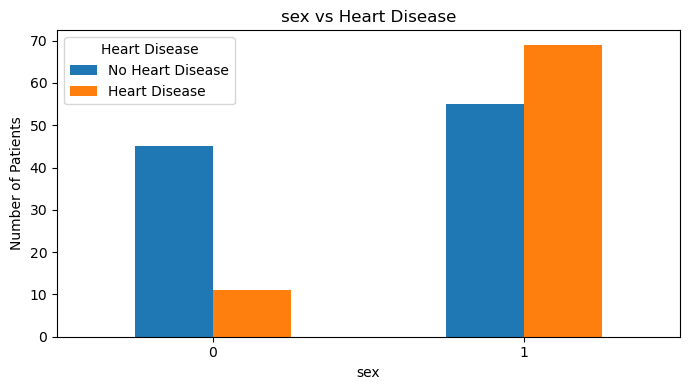

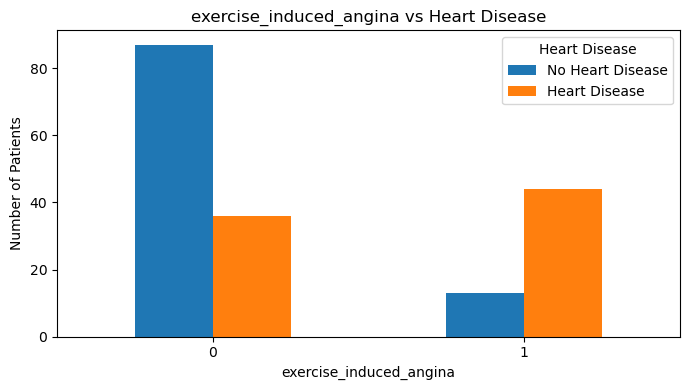

In [29]:
# Visualize Categorical Features

for column in categorical_columns:
    pd.crosstab(
        df[column],
        df["heart_disease_present"]
    ).plot(
        kind="bar",
        figsize=(7, 4)
    )
    
    plt.title(f"{column} vs Heart Disease")
    plt.xlabel(column)
    plt.ylabel("Number of Patients")
    plt.xticks(rotation=0)
    plt.legend(
        ["No Heart Disease", "Heart Disease"],
        title="Heart Disease"
    )
    plt.tight_layout()
    plt.show()

In [30]:
# Correlation with Heart Disease

numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()["heart_disease_present"].sort_values(
    ascending=False
)

correlation

heart_disease_present                   1.000000
exercise_induced_angina                 0.448647
num_major_vessels                       0.421519
chest_pain_type                         0.412829
oldpeak_eq_st_depression                0.382930
slope_of_peak_exercise_st_segment       0.344224
sex                                     0.335421
resting_ekg_results                     0.145933
age                                     0.138255
serum_cholesterol_mg_per_dl             0.079775
resting_blood_pressure                  0.078506
fasting_blood_sugar_gt_120_mg_per_dl    0.003379
max_heart_rate_achieved                -0.375352
Name: heart_disease_present, dtype: float64

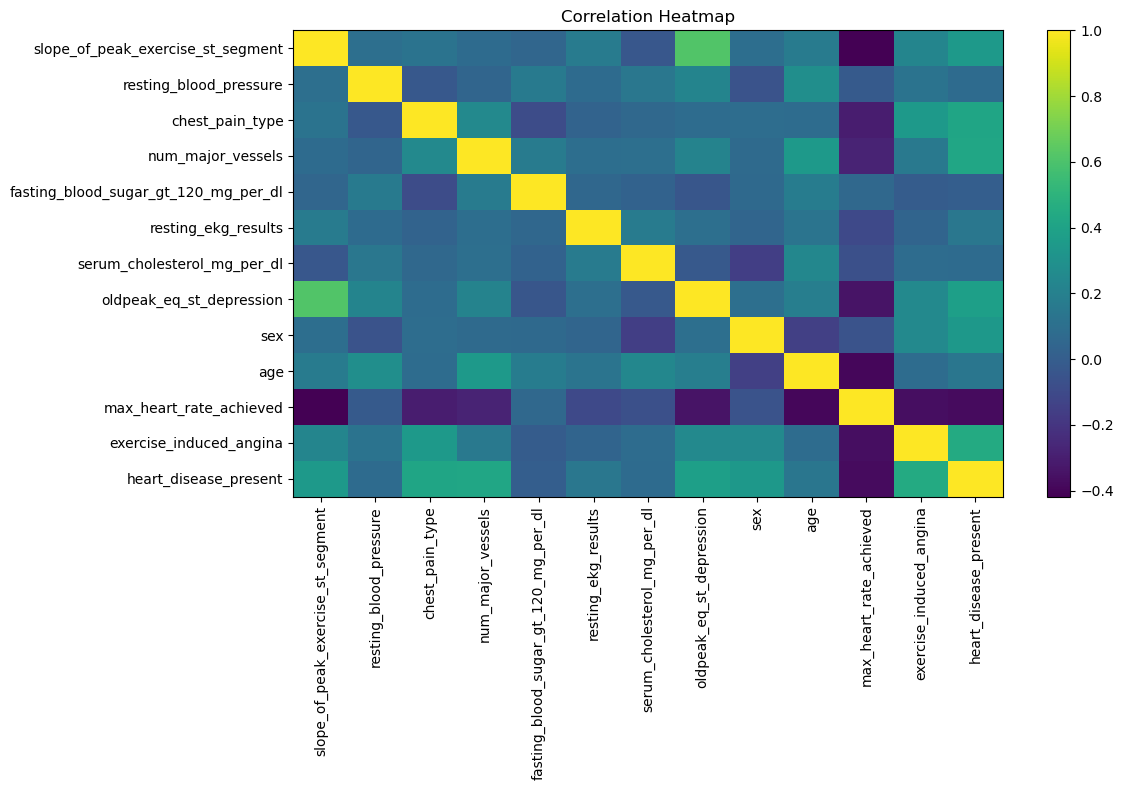

In [31]:
# Correlation Heatmap

plt.figure(figsize=(12, 8))

correlation_matrix = numeric_df.corr()

plt.imshow(correlation_matrix, aspect="auto")

plt.colorbar()

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.show()

## Exploratory Data Analysis - Key Observations

- The dataset contains 180 patient records and 15 columns after combining the patient features with the target variable.
- There are no missing values in the dataset.
- There are no duplicate patient IDs.
- The target variable contains two classes: 0 (no heart disease) and 1 (heart disease present).
- The dataset contains numerical, binary, and categorical features.
- Patients with heart disease generally show a higher average age compared with patients without heart disease.
- The average maximum heart rate achieved is lower for patients with heart disease.
- Oldpeak (ST depression) shows a noticeable difference between patients with and without heart disease.
- The categorical feature analysis shows differences in heart disease distribution across chest pain type, thal, exercise-induced angina, slope of peak exercise ST segment, and number of major vessels.
- Some numerical features contain potential outliers, which were identified using boxplots.
- Correlation analysis was performed to understand the relationships between numerical features and the heart disease target.

In [32]:
# Remove Patient ID

df = df.drop("patient_id", axis=1)

df.head()

,slope_of_peak_exercise_st_segment,thal,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,heart_disease_present
0,1,normal,128,2,0,0,2,308,0.0,1,45,170,0,0
1,2,normal,110,3,0,0,0,214,1.6,0,54,158,0,0
2,1,normal,125,4,3,0,2,304,0.0,1,77,162,1,1
3,1,reversible_defect,152,4,0,0,0,223,0.0,1,40,181,0,1
4,3,reversible_defect,178,1,0,0,2,270,4.2,1,59,145,0,0


In [33]:
# Separate Features and Target

X = df.drop("heart_disease_present", axis=1)
y = df["heart_disease_present"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (180, 13)
Target Shape: (180,)


In [34]:
# Check Feature Data Types

X.dtypes

slope_of_peak_exercise_st_segment         int64
thal                                     object
resting_blood_pressure                    int64
chest_pain_type                           int64
num_major_vessels                         int64
fasting_blood_sugar_gt_120_mg_per_dl      int64
resting_ekg_results                       int64
serum_cholesterol_mg_per_dl               int64
oldpeak_eq_st_depression                float64
sex                                       int64
age                                       int64
max_heart_rate_achieved                   int64
exercise_induced_angina                   int64
dtype: object

In [35]:
# Encode Categorical Feature

X = pd.get_dummies(
    X,
    columns=["thal"],
    drop_first=True
)

X.head()

,slope_of_peak_exercise_st_segment,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,thal_normal,thal_reversible_defect
0,1,128,2,0,0,2,308,0.0,1,45,170,0,True,False
1,2,110,3,0,0,0,214,1.6,0,54,158,0,True,False
2,1,125,4,3,0,2,304,0.0,1,77,162,1,True,False
3,1,152,4,0,0,0,223,0.0,1,40,181,0,False,True
4,3,178,1,0,0,2,270,4.2,1,59,145,0,False,True


In [36]:
# Check Columns After Encoding

print("Features Shape:", X.shape)
print("\nColumns:")
print(X.columns.tolist())

Features Shape: (180, 14)

Columns:
['slope_of_peak_exercise_st_segment', 'resting_blood_pressure', 'chest_pain_type', 'num_major_vessels', 'fasting_blood_sugar_gt_120_mg_per_dl', 'resting_ekg_results', 'serum_cholesterol_mg_per_dl', 'oldpeak_eq_st_depression', 'sex', 'age', 'max_heart_rate_achieved', 'exercise_induced_angina', 'thal_normal', 'thal_reversible_defect']


In [37]:
# Check Data Types After Encoding

X.dtypes

slope_of_peak_exercise_st_segment         int64
resting_blood_pressure                    int64
chest_pain_type                           int64
num_major_vessels                         int64
fasting_blood_sugar_gt_120_mg_per_dl      int64
resting_ekg_results                       int64
serum_cholesterol_mg_per_dl               int64
oldpeak_eq_st_depression                float64
sex                                       int64
age                                       int64
max_heart_rate_achieved                   int64
exercise_induced_angina                   int64
thal_normal                                bool
thal_reversible_defect                     bool
dtype: object

In [38]:
# Check Missing Values After Encoding

X.isnull().sum()

slope_of_peak_exercise_st_segment       0
resting_blood_pressure                  0
chest_pain_type                         0
num_major_vessels                       0
fasting_blood_sugar_gt_120_mg_per_dl    0
resting_ekg_results                     0
serum_cholesterol_mg_per_dl             0
oldpeak_eq_st_depression                0
sex                                     0
age                                     0
max_heart_rate_achieved                 0
exercise_induced_angina                 0
thal_normal                             0
thal_reversible_defect                  0
dtype: int64

In [39]:
# Display Final Feature Dataset

X.head()

,slope_of_peak_exercise_st_segment,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,thal_normal,thal_reversible_defect
0,1,128,2,0,0,2,308,0.0,1,45,170,0,True,False
1,2,110,3,0,0,0,214,1.6,0,54,158,0,True,False
2,1,125,4,3,0,2,304,0.0,1,77,162,1,True,False
3,1,152,4,0,0,0,223,0.0,1,40,181,0,False,True
4,3,178,1,0,0,2,270,4.2,1,59,145,0,False,True


In [40]:
# Split Data into Training and Testing Sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)

X_train Shape: (144, 14)
X_test Shape: (36, 14)
y_train Shape: (144,)
y_test Shape: (36,)


In [41]:
# Check Target Distribution After Train-Test Split

print("Training Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Target Distribution:
heart_disease_present
0    80
1    64
Name: count, dtype: int64

Testing Target Distribution:
heart_disease_present
0    20
1    16
Name: count, dtype: int64


In [42]:
# Convert Boolean Features to Integer

boolean_columns = [
    "thal_normal",
    "thal_reversible_defect"
]

X_train[boolean_columns] = X_train[boolean_columns].astype(int)
X_test[boolean_columns] = X_test[boolean_columns].astype(int)

X_train.head()

,slope_of_peak_exercise_st_segment,resting_blood_pressure,chest_pain_type,num_major_vessels,fasting_blood_sugar_gt_120_mg_per_dl,resting_ekg_results,serum_cholesterol_mg_per_dl,oldpeak_eq_st_depression,sex,age,max_heart_rate_achieved,exercise_induced_angina,thal_normal,thal_reversible_defect
139,1,130,2,0,0,2,219,0.0,1,44,188,0,1,0
0,1,128,2,0,0,2,308,0.0,1,45,170,0,1,0
169,2,110,1,0,0,2,211,1.8,1,64,144,1,1,0
65,1,126,4,0,0,2,282,0.0,1,35,156,1,0,1
98,1,155,3,0,0,0,269,0.8,0,65,148,0,1,0


In [43]:
# Check Final Feature Data Types

X_train.dtypes

slope_of_peak_exercise_st_segment         int64
resting_blood_pressure                    int64
chest_pain_type                           int64
num_major_vessels                         int64
fasting_blood_sugar_gt_120_mg_per_dl      int64
resting_ekg_results                       int64
serum_cholesterol_mg_per_dl               int64
oldpeak_eq_st_depression                float64
sex                                       int64
age                                       int64
max_heart_rate_achieved                   int64
exercise_induced_angina                   int64
thal_normal                               int64
thal_reversible_defect                    int64
dtype: object

In [44]:
# Import StandardScaler

from sklearn.preprocessing import StandardScaler

In [45]:
# Create StandardScaler

scaler = StandardScaler()

In [46]:
# Scale Training and Testing Features

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

Scaled Training Shape: (144, 14)
Scaled Testing Shape: (36, 14)


In [47]:
# Display Scaled Training Data

X_train_scaled[:5]

array([[-0.83939296, -0.02468392, -1.2808703 , -0.72932496, -0.49130368,
         0.97259753, -0.54018878, -0.8927209 ,  0.66332496, -1.10628448,
         1.73202176, -0.68511879,  0.8819171 , -0.79772404],
       [-0.83939296, -0.14940269, -1.2808703 , -0.72932496, -0.49130368,
         0.97259753,  1.11288176, -0.8927209 ,  0.66332496, -1.00324116,
         0.91144044, -0.68511879,  0.8819171 , -0.79772404],
       [ 0.79402037, -1.27187163, -2.3919867 , -0.72932496, -0.49130368,
         0.97259753, -0.6887794 ,  0.78161526,  0.66332496,  0.95458182,
        -0.27384369,  1.4596009 ,  0.8819171 , -0.79772404],
       [-0.83939296, -0.27412146,  0.94136251, -0.72932496, -0.49130368,
         0.97259753,  0.62996228, -0.8927209 ,  0.66332496, -2.03367431,
         0.27321052,  1.4596009 , -1.13389342,  1.25356634],
       [-0.83939296,  1.53430071, -0.16975389, -0.72932496, -0.49130368,
        -1.02817453,  0.38850254, -0.1485715 , -1.50755672,  1.05762513,
        -0.09149228, -0.68

In [48]:
# Import Logistic Regression

from sklearn.linear_model import LogisticRegression

In [49]:
# Create Logistic Regression Model

logistic_model = LogisticRegression(random_state=42)

In [50]:
# Train Logistic Regression Model

logistic_model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [51]:
# Make Predictions Using Logistic Regression

y_pred_logistic = logistic_model.predict(X_test_scaled)

y_pred_logistic

array([0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1,
       1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1])

In [52]:
# Evaluate Logistic Regression Accuracy

from sklearn.metrics import accuracy_score

logistic_accuracy = accuracy_score(
    y_test,
    y_pred_logistic
)

print("Logistic Regression Accuracy:", logistic_accuracy)

Logistic Regression Accuracy: 0.8333333333333334


In [53]:
# Classification Report for Logistic Regression

from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_logistic
    )
)

              precision    recall  f1-score   support

           0       0.89      0.80      0.84        20
           1       0.78      0.88      0.82        16

    accuracy                           0.83        36
   macro avg       0.83      0.84      0.83        36
weighted avg       0.84      0.83      0.83        36



In [54]:
# Confusion Matrix for Logistic Regression

from sklearn.metrics import confusion_matrix

logistic_cm = confusion_matrix(
    y_test,
    y_pred_logistic
)

print(logistic_cm)

[[16  4]
 [ 2 14]]


In [55]:
# Import Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier

In [56]:
# Create Decision Tree Model

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

In [57]:
# Train Decision Tree Model

decision_tree_model.fit(
    X_train,
    y_train
)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [58]:
# Make Predictions Using Decision Tree

y_pred_tree = decision_tree_model.predict(X_test)

y_pred_tree

array([1, 1, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1,
       0, 0, 0, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0])

In [59]:
# Evaluate Decision Tree Accuracy

tree_accuracy = accuracy_score(
    y_test,
    y_pred_tree
)

print("Decision Tree Accuracy:", tree_accuracy)

Decision Tree Accuracy: 0.8055555555555556


In [60]:
# Classification Report for Decision Tree

print(
    classification_report(
        y_test,
        y_pred_tree
    )
)

              precision    recall  f1-score   support

           0       0.84      0.80      0.82        20
           1       0.76      0.81      0.79        16

    accuracy                           0.81        36
   macro avg       0.80      0.81      0.80        36
weighted avg       0.81      0.81      0.81        36



In [61]:
# Confusion Matrix for Decision Tree

tree_cm = confusion_matrix(
    y_test,
    y_pred_tree
)

print(tree_cm)

[[16  4]
 [ 3 13]]


In [62]:
# Import Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

In [63]:
# Create Random Forest Model

random_forest_model = RandomForestClassifier(
    random_state=42
)

In [64]:
# Train Random Forest Model

random_forest_model.fit(
    X_train,
    y_train
)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [65]:
# Make Predictions Using Random Forest

y_pred_forest = random_forest_model.predict(X_test)

y_pred_forest

array([0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1,
       1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1])

In [66]:
# Evaluate Random Forest Accuracy

forest_accuracy = accuracy_score(
    y_test,
    y_pred_forest
)

print("Random Forest Accuracy:", forest_accuracy)

Random Forest Accuracy: 0.8611111111111112


In [67]:
# Classification Report for Random Forest

from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred_forest
    )
)

              precision    recall  f1-score   support

           0       0.94      0.80      0.86        20
           1       0.79      0.94      0.86        16

    accuracy                           0.86        36
   macro avg       0.87      0.87      0.86        36
weighted avg       0.87      0.86      0.86        36



In [68]:
# Confusion Matrix for Random Forest

from sklearn.metrics import confusion_matrix

forest_cm = confusion_matrix(
    y_test,
    y_pred_forest
)

print(forest_cm)

[[16  4]
 [ 1 15]]


In [69]:
# Import K-Nearest Neighbors

from sklearn.neighbors import KNeighborsClassifier

In [70]:
# Create KNN Model

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

In [71]:
# Train KNN Model

knn_model.fit(
    X_train_scaled,
    y_train
)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [72]:
# Make Predictions Using KNN

y_pred_knn = knn_model.predict(X_test_scaled)

y_pred_knn

array([0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1,
       0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1])

In [73]:
# Evaluate KNN Accuracy

knn_accuracy = accuracy_score(
    y_test,
    y_pred_knn
)

print("KNN Accuracy:", knn_accuracy)

KNN Accuracy: 0.8333333333333334


In [74]:
# Classification Report for KNN

print(
    classification_report(
        y_test,
        y_pred_knn
    )
)

              precision    recall  f1-score   support

           0       0.89      0.80      0.84        20
           1       0.78      0.88      0.82        16

    accuracy                           0.83        36
   macro avg       0.83      0.84      0.83        36
weighted avg       0.84      0.83      0.83        36



In [75]:
# Confusion Matrix for KNN

knn_cm = confusion_matrix(
    y_test,
    y_pred_knn
)

print(knn_cm)

[[16  4]
 [ 2 14]]


In [76]:
# Import Support Vector Classifier

from sklearn.svm import SVC

In [77]:
# Create SVM Model

svm_model = SVC(
    random_state=42
)

In [78]:
# Train SVM Model

svm_model.fit(
    X_train_scaled,
    y_train
)

,C,1.0
,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [79]:
# Make Predictions Using SVM

y_pred_svm = svm_model.predict(X_test_scaled)

y_pred_svm

array([0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1,
       1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1])

In [80]:
# Evaluate SVM Accuracy

svm_accuracy = accuracy_score(
    y_test,
    y_pred_svm
)

print("SVM Accuracy:", svm_accuracy)

SVM Accuracy: 0.8611111111111112


In [81]:
# Classification Report for SVM

print(
    classification_report(
        y_test,
        y_pred_svm
    )
)

              precision    recall  f1-score   support

           0       0.89      0.85      0.87        20
           1       0.82      0.88      0.85        16

    accuracy                           0.86        36
   macro avg       0.86      0.86      0.86        36
weighted avg       0.86      0.86      0.86        36



In [82]:
# Confusion Matrix for SVM

svm_cm = confusion_matrix(
    y_test,
    y_pred_svm
)

print(svm_cm)

[[17  3]
 [ 2 14]]


In [83]:
# Import Gaussian Naive Bayes

from sklearn.naive_bayes import GaussianNB

In [84]:
# Create Naive Bayes Model

naive_bayes_model = GaussianNB()

In [85]:
# Train Naive Bayes Model

naive_bayes_model.fit(
    X_train_scaled,
    y_train
)

,priors,None
,var_smoothing,1e-09


In [86]:
# Make Predictions Using Naive Bayes

y_pred_nb = naive_bayes_model.predict(X_test_scaled)

y_pred_nb

array([0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1,
       1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1])

In [87]:
# Evaluate Naive Bayes Accuracy

nb_accuracy = accuracy_score(
    y_test,
    y_pred_nb
)

print("Naive Bayes Accuracy:", nb_accuracy)

Naive Bayes Accuracy: 0.8611111111111112


In [88]:
# Classification Report for Naive Bayes

print(
    classification_report(
        y_test,
        y_pred_nb
    )
)

              precision    recall  f1-score   support

           0       0.94      0.80      0.86        20
           1       0.79      0.94      0.86        16

    accuracy                           0.86        36
   macro avg       0.87      0.87      0.86        36
weighted avg       0.87      0.86      0.86        36



In [89]:
# Confusion Matrix for Naive Bayes

nb_cm = confusion_matrix(
    y_test,
    y_pred_nb
)

print(nb_cm)

[[16  4]
 [ 1 15]]


## Model Comparison Report

The performance of multiple Machine Learning models was evaluated using accuracy, precision, recall, and F1-score.

The comparison helps identify the most suitable model for predicting heart disease.

In [90]:
# Create Model Comparison Report

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "KNN",
        "SVM",
        "Naive Bayes"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_logistic),
        accuracy_score(y_test, y_pred_tree),
        accuracy_score(y_test, y_pred_forest),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_nb)
    ],
    "Precision": [
        precision_score(y_test, y_pred_logistic),
        precision_score(y_test, y_pred_tree),
        precision_score(y_test, y_pred_forest),
        precision_score(y_test, y_pred_knn),
        precision_score(y_test, y_pred_svm),
        precision_score(y_test, y_pred_nb)
    ],
    "Recall": [
        recall_score(y_test, y_pred_logistic),
        recall_score(y_test, y_pred_tree),
        recall_score(y_test, y_pred_forest),
        recall_score(y_test, y_pred_knn),
        recall_score(y_test, y_pred_svm),
        recall_score(y_test, y_pred_nb)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_logistic),
        f1_score(y_test, y_pred_tree),
        f1_score(y_test, y_pred_forest),
        f1_score(y_test, y_pred_knn),
        f1_score(y_test, y_pred_svm),
        f1_score(y_test, y_pred_nb)
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.833333,0.777778,0.8750,0.823529
1,Decision Tree,0.805556,0.764706,0.8125,0.787879
2,Random Forest,0.861111,0.789474,0.9375,0.857143
3,KNN,0.833333,0.777778,0.8750,0.823529
4,SVM,0.861111,0.823529,0.8750,0.848485
5,Naive Bayes,0.861111,0.789474,0.9375,0.857143


## Model Performance Comparison

The following visualization compares the accuracy of the Machine Learning models evaluated in this project.

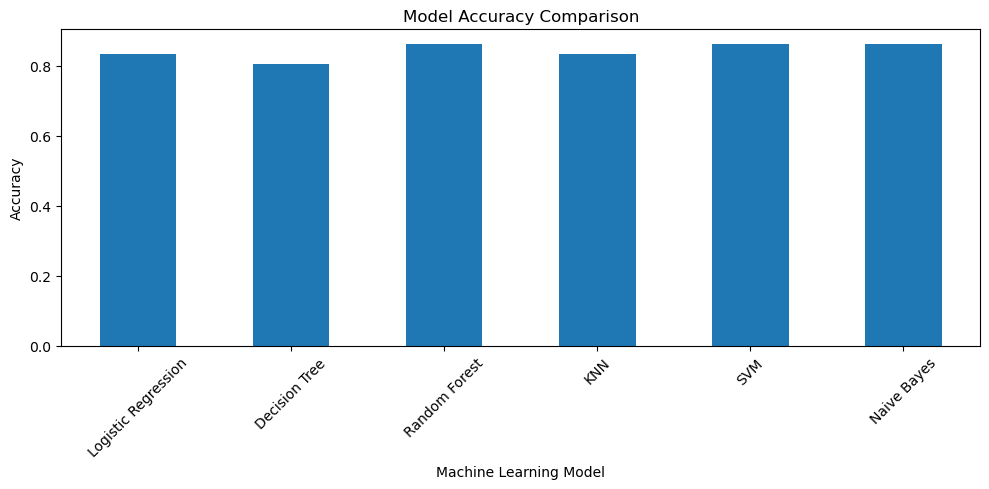

In [91]:
# Visualize Model Accuracy

model_comparison.plot(
    x="Model",
    y="Accuracy",
    kind="bar",
    legend=False,
    figsize=(10, 5)
)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Best Model Recommendation

Based on the model comparison, Random Forest and Naive Bayes achieved the highest performance on the test dataset.

Both models achieved:
- Accuracy of 86.11%
- Recall of 93.75% for heart disease
- F1-score of 85.71%

Random Forest is selected as the preferred model for this project because it provides strong predictive performance and can capture complex relationships between multiple patient features.

Therefore, Random Forest is recommended as the best-performing model for this project.

## Random Forest Feature Importance

Feature importance helps identify which patient features contributed most to the predictions made by the Random Forest model.

In [92]:
# Calculate Random Forest Feature Importance

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
12,thal_normal,0.107230
9,age,0.104026
10,max_heart_rate_achieved,0.101994
13,thal_reversible_defect,0.101338
7,oldpeak_eq_st_depression,0.096840
6,serum_cholesterol_mg_per_dl,0.096613
2,chest_pain_type,0.090714
1,resting_blood_pressure,0.076526
3,num_major_vessels,0.064919
11,exercise_induced_angina,0.049577


### Feature Importance Observation

The feature importance results show which patient characteristics contributed most to the Random Forest model's predictions. These features can help understand the factors that the model considered important when making predictions.

Feature importance indicates model behavior and should not be interpreted as medical causation.

## Challenges Faced and Techniques Used

### Challenge 1: Categorical Data

The `thal` feature is a categorical variable containing different categories such as normal, fixed_defect, and reversible_defect.

**Technique Used:** One-hot encoding was applied to convert the categorical values into numerical features.

**Reason:** Machine Learning models require numerical input, so categorical values were converted into separate binary columns.

### Challenge 2: Different Feature Scales

The dataset contains features with different numerical ranges, such as age, blood pressure, cholesterol, and maximum heart rate.

**Technique Used:** StandardScaler was used to standardize the features for models such as Logistic Regression, KNN, SVM, and Naive Bayes.

**Reason:** Scaling prevents features with larger numerical ranges from having an unnecessary influence on distance-based and scale-sensitive models.

### Challenge 3: Small Dataset

The dataset contains only 180 patient records.

**Technique Used:** The data was divided into training and testing sets using an 80:20 split with stratification.

**Reason:** Stratification was used to maintain a similar distribution of the two target classes in both training and testing data.

### Challenge 4: Potential Outliers

Boxplot analysis showed potential outliers in some numerical features.

**Technique Used:** The outliers were identified during EDA but were not automatically removed.

**Reason:** In healthcare data, unusual values may represent genuine patient conditions. Therefore, removing them without sufficient evidence could result in loss of useful information.

## Testing the Final Model

The Random Forest model was selected as the preferred model based on the model comparison results.

The model is now tested on unseen test data to compare the actual heart disease labels with the predicted values.

In [93]:
# Test the Final Random Forest Model

test_results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred_forest
})

test_results.head(10)

,Actual,Predicted
0,0,0
1,1,1
2,1,1
3,0,0
4,0,0
5,1,0
6,0,1
7,0,0
8,0,1
9,1,1


## Sample Patient Prediction

A sample patient from the unseen test dataset is used to demonstrate how the final Random Forest model generates a prediction.

In [94]:
# Test a Single Patient Prediction

sample_patient = X_test.iloc[[0]]

sample_prediction = random_forest_model.predict(sample_patient)

print("Predicted Heart Disease:", sample_prediction[0])

if sample_prediction[0] == 1:
    print("Prediction: Heart disease may be present.")
else:
    print("Prediction: Heart disease may not be present.")

Predicted Heart Disease: 0
Prediction: Heart disease may not be present.


## Suggestions to the Hospital

Based on the analysis and Machine Learning predictions, the following suggestions can be provided to the hospital:

### 1. Early Risk Identification

The hospital can use the prediction model to identify patients who may have a higher risk of heart disease and prioritize them for further medical evaluation.

### 2. Detailed Medical Assessment

Patients predicted to be at higher risk should undergo appropriate clinical assessment and diagnostic tests recommended by qualified healthcare professionals.

### 3. Regular Monitoring

Patients identified as being at higher risk can be monitored regularly using relevant health measurements such as blood pressure, cholesterol levels, heart rate, and other clinical indicators.

### 4. Preventive Care

The hospital can encourage appropriate preventive-care practices and provide patients with guidance on maintaining a healthy lifestyle, based on medical advice.

### 5. Use Predictions as a Support Tool

The Machine Learning model should be used as a decision-support tool rather than as a replacement for doctors or clinical diagnosis.

### 6. Continuous Model Evaluation

The model should be regularly evaluated using new and representative patient data to ensure that its performance remains reliable before considering any real-world deployment.

## Project Conclusion

In this project, patient cardiovascular data was analyzed and Machine Learning classification models were developed to predict the presence of heart disease.

The dataset was explored using statistical analysis and visualizations. Data preprocessing included categorical encoding, feature scaling, and splitting the data into training and testing sets.

Six Machine Learning models were evaluated:
- Logistic Regression
- Decision Tree
- Random Forest
- K-Nearest Neighbors (KNN)
- Support Vector Machine (SVM)
- Gaussian Naive Bayes

The Random Forest model showed promising performance on the available test dataset and can be considered a decision-support model for this academic project. However, the dataset contains only 180 patient records, so further validation using larger and representative clinical datasets, along with clinical evaluation, would be required before any real-world clinical deployment.